# Modelamiento supervisado de datos biométricos de un smartwatch

**Evaluación Parcial 3 · Encargo Machine Learning supervisado**

### Integrantes:
- VINCENT FARENDEN CERÓN
- RODRIGO IGNACIO MARTÍNEZ BECKER
- DIEGO IGNACIO PEÑA Y LILLO LUHRS

### Asignatura:
- MACHINE LEARNING_001D

### Profesor:
- FRANCISCO JAVIER JEREZ SALAZAR

### Fecha:
- 18-10-2026

---

## Introducción y objetivo del informe

Este informe da continuidad al trabajo de la Evaluación Parcial 1, en la que se limpió y
preparó un conjunto de 10.000 registros biométricos capturados por un smartwatch
(`01_limpieza_health_data.ipynb`). En esta segunda etapa se implementan, optimizan y
evalúan modelos de **aprendizaje supervisado** sobre esos mismos datos, con el fin de
responder a dos preguntas de negocio planteadas por el equipo:

| Problema | Tipo | Pregunta de negocio |
| --- | --- | --- |
| Estimar la duración del sueño | Regresión | ¿Se pueden estimar las horas dormidas de un usuario a partir de las mediciones del día (pulso, oxigenación, pasos, actividad y estrés), para detectar déficit de sueño en las noches en que no usa el reloj? |
| Detectar estrés alto | Clasificación | ¿Se puede identificar a un usuario con estrés alto (nivel 7 o superior) a partir de las mediciones pasivas del dispositivo, para enviarle una alerta preventiva sin pedirle que lo declare? |

El informe se organiza en los siguientes apartados:

1. Preparación de los datos y del flujo de preprocesamiento.
2. Modelamiento de regresión.
3. Modelamiento de clasificación.
4. Prueba de significancia por permutación.
5. Selección y análisis de resultados.
6. Conclusiones.

> **Adelanto del resultado.** En la EP1 se observó que las variables del conjunto no están
> correlacionadas entre sí. Este informe comprueba, con validación cruzada y una prueba
> estadística formal, que esa ausencia de relación impide que cualquier modelo supere a una
> predicción trivial. El valor del trabajo está en demostrarlo con rigor y en no reportar
> como "aprendizaje" lo que es ruido.

### Correspondencia con el encargo

| Apartado del encargo | Indicador | Dónde se desarrolla |
| --- | --- | --- |
| 1a. Objetivo de predicción | IE1 | 2 › Objetivo de predicción |
| 1b. Al menos dos algoritmos de regresión | IE1 | 2 › Modelos e hiperparámetros explorados (Ridge, KNN y Random Forest) |
| 1c. Mejor configuración de cada modelo | IE1 | 1 › Funciones auxiliares (`GridSearchCV` con validación cruzada de 5 pliegues) y 2 › Exploración de hiperparámetros |
| 1d. MSE, RMSE y R² | IE2 | 2 › Métricas de evaluación, Resultados de la validación cruzada y Evaluación en el conjunto de prueba |
| 2a. Objetivo de clasificación | IE3 | 3 › Objetivo de clasificación |
| 2b. Desbalance y técnicas de balanceo | IE4 | 3 › Verificación del desbalance y Comparación de técnicas de balanceo |
| 2c. Al menos tres algoritmos de clasificación | IE3 | 3 › Modelos e hiperparámetros explorados (regresión logística, KNN, árbol de decisión y Random Forest) |
| 2d. Optimización de hiperparámetros | IE3 | 3 › Optimización del Random Forest |
| 2e. Métricas de clasificación | IE5 | 3 › Métricas de evaluación y Evaluación en el conjunto de prueba (matrices de confusión, curvas ROC y reporte) |
| 3a. Tabla resumen | IE7 | 5 › Tablas resumen de regresión y de clasificación |
| 3b. Mejor modelo de cada tipo | IE7 | 5 › Mejor modelo de regresión y Mejor modelo de clasificación |
| 3c. Justificación de la elección | IE6 | 5 › Párrafos «Criterio» de cada mejor modelo, apoyados en 4 › Prueba de significancia por permutación |

### Declaración de uso de inteligencia artificial

De acuerdo con las indicaciones de la evaluación, se declara el uso de **Claude (Anthropic)**
como herramienta de apoyo para:

- Proponer la estructura del notebook y revisar la redacción de las secciones en Markdown.
- Sugerir y depurar fragmentos de código de `scikit-learn` e `imbalanced-learn`.
- Detectar la fuga de datos presente en el preprocesamiento de la EP1 (escalado ajustado
  sobre el conjunto completo).
- Revisar el notebook contra la pauta de evaluación, corregir inconsistencias de redacción y
  formato, y generar el resumen visual del proceso (`reports/proceso_y_decisiones_EV2.html`).

Todo el contenido generado fue revisado, ejecutado y validado por el equipo, que es
responsable de las decisiones técnicas y de la interpretación de los resultados. La
referencia de la herramienta se incluye al final del informe, según la guía de
Bibliotecas Duoc UC.

---

## 1. Preparación de los datos

### Librerías y configuración general

Se fija una semilla (`SEMILLA = 42`) en todas las operaciones aleatorias (partición,
validación cruzada, modelos y sobremuestreo) para que el notebook sea reproducible. Las
versiones de las librerías se imprimen al final de la celda siguiente y están fijadas en
`requirements.txt`, en la raíz del repositorio.

**Convención numérica.** El texto del informe usa la coma decimal del español (por ejemplo,
0,58). Las tablas y los gráficos generados por Python usan el punto decimal (0.58), que es el
formato por defecto de las librerías.

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import imblearn

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OrdinalEncoder, FunctionTransformer
from sklearn.model_selection import (train_test_split, KFold, StratifiedKFold,
                                     GridSearchCV, permutation_test_score)
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import (mean_squared_error, root_mean_squared_error,
                             mean_absolute_error, mean_absolute_percentage_error, r2_score,
                             accuracy_score, balanced_accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score, roc_curve,
                             confusion_matrix, classification_report, make_scorer)

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:.4f}")
pd.set_option("display.max_colwidth", None)

SEMILLA = 42

# Estilo de gráficos: grilla tenue y un color fijo por modelo (el color sigue al
# modelo en todos los gráficos, nunca a su posición en el ranking).
sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "axes.edgecolor": "#c3c2b7", "grid.color": "#e1e0d9", "axes.titlesize": 11,
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "figure.dpi": 100,
})
COLORES = {
    "Línea base": "#898781",
    "Línea base (azar)": "#898781",
    "Línea base (mayoritaria)": "#c3c2b7",
    "Ridge": "#2a78d6",
    "Regresión logística": "#2a78d6",
    "KNN": "#eb6834",
    "Random Forest": "#1baf7a",
    "Árbol de decisión": "#eda100",
}

print(f"Python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"scikit-learn {sklearn.__version__} | imbalanced-learn {imblearn.__version__} | "
      f"matplotlib {matplotlib.__version__} | seaborn {sns.__version__}")

Python 3.14.4 | numpy 2.4.4 | pandas 3.0.2 | scikit-learn 1.9.0 | imbalanced-learn 0.14.2 | matplotlib 3.10.8 | seaborn 0.13.2


### Reconstrucción del conjunto limpio

Se reaplican las reglas de limpieza **deterministas** de la EP1, es decir, las que operan
registro a registro y no dependen de estadísticos calculados sobre el conjunto:

| Regla (EP1) | Tratamiento |
| --- | --- |
| `User ID` es un identificador sin valor predictivo | Se descarta |
| `Sleep Duration (hours)` y `Stress Level` contienen `"ERROR"` y `"Very High"` | Conversión a número; los textos pasan a `NaN` |
| `Activity Level` tiene 6 etiquetas para 3 niveles | Diccionario de equivalencias |
| Pulsos sobre 200 bpm y el valor centinela 40,0 | Pasan a `NaN` |
| Duración de sueño negativa | Pasa a `NaN` |

**Cambio respecto de la EP1: imputación y escalamiento se trasladan al pipeline.** En la
EP1 la mediana de imputación y los parámetros de `StandardScaler` y `MinMaxScaler` se
calcularon sobre los 10.000 registros. Si se usara ese archivo (`model.csv`) para entrenar,
el conjunto de prueba habría influido en la transformación de los datos de entrenamiento:
una **fuga de información** que infla las métricas. Por eso aquí la imputación y el
escalamiento se ajustan **solo con el conjunto de entrenamiento**, dentro de un `Pipeline`
que se reentrena en cada pliegue de la validación cruzada.

Las reglas y estrategias son las mismas de la EP1: mediana para las continuas, mediana
redondeada para `Stress Level` (para que el valor imputado pertenezca a la escala entera
1–10), moda para `Activity Level`, `OrdinalEncoder` con orden explícito, Z-score para las
continuas y Min-Max para las ordinales. Solo cambia **en qué momento** se calculan.

Por esta razón se parte del CSV original y no del archivo exportado en la EP1: se obtiene el
mismo conjunto preprocesado, con las mismas reglas, pero sin la fuga de información.

In [2]:
RUTA_DATOS = Path("../data/raw/unclean_smartwatch_health_data.csv")
# Si el notebook se abre fuera del repositorio (por ejemplo, en Google Colab), los datos se
# leen desde la copia pública del repositorio en GitHub.
URL_DATOS = ("https://raw.githubusercontent.com/ByFlopp/Limpieza-Health-Data/main/"
             "data/raw/unclean_smartwatch_health_data.csv")

crudo = pd.read_csv(RUTA_DATOS if RUTA_DATOS.exists() else URL_DATOS)

# Se conserva el texto original de estrés: "Very High" se usa más adelante para la
# etiqueta de clasificación.
estres_original = crudo["Stress Level"].copy()

datos = crudo.drop(columns=["User ID"])

for columna in ["Sleep Duration (hours)", "Stress Level"]:
    datos[columna] = pd.to_numeric(datos[columna], errors="coerce")

datos["Activity Level"] = datos["Activity Level"].replace({
    "Seddentary": "Sedentary",
    "Actve": "Active",
    "Highly_Active": "Highly Active",
})

pulso_invalido = (datos["Heart Rate (BPM)"] > 200) | (datos["Heart Rate (BPM)"] == 40.0)
datos.loc[pulso_invalido, "Heart Rate (BPM)"] = np.nan
datos.loc[datos["Sleep Duration (hours)"] < 0, "Sleep Duration (hours)"] = np.nan

print(f"Dimensiones: {datos.shape}")
print(f"Pulsos inválidos marcados como NaN: {pulso_invalido.sum()}")
print(f"Categorías de actividad: {sorted(datos['Activity Level'].dropna().unique())}")

pd.DataFrame({
    "tipo": datos.dtypes.astype(str),
    "nulos": datos.isna().sum(),
    "% nulos": (datos.isna().mean() * 100).round(2),
})

Dimensiones: (10000, 6)
Pulsos inválidos marcados como NaN: 134
Categorías de actividad: ['Active', 'Highly Active', 'Sedentary']


,tipo,nulos,% nulos
Heart Rate (BPM),float64,534,5.3400
Blood Oxygen Level (%),float64,300,3.0000
Step Count,float64,100,1.0000
Sleep Duration (hours),float64,398,3.9800
Activity Level,str,200,2.0000
Stress Level,float64,249,2.4900


### Preprocesador común

El preprocesamiento se encapsula en una función que construye un `ColumnTransformer` según
las variables de entrada de cada problema. Así, regresión y clasificación comparten
exactamente las mismas reglas.

In [3]:
CONTINUAS = ["Heart Rate (BPM)", "Blood Oxygen Level (%)", "Step Count",
             "Sleep Duration (hours)"]
ORDEN_ACTIVIDAD = ["Sedentary", "Active", "Highly Active"]


def construir_preprocesador(columnas):
    """ColumnTransformer con las reglas de la EP1, ajustado solo con datos de entrenamiento."""
    transformadores = []

    continuas = [c for c in CONTINUAS if c in columnas]
    transformadores.append(("continuas", Pipeline([
        ("imputar", SimpleImputer(strategy="median")),
        ("escalar", StandardScaler()),
    ]), continuas))

    if "Stress Level" in columnas:
        # Mediana redondeada, como en la EP1: el valor imputado queda dentro de la escala 1-10.
        transformadores.append(("estres", Pipeline([
            ("imputar", SimpleImputer(strategy="median")),
            ("redondear", FunctionTransformer(np.round, feature_names_out="one-to-one")),
            ("escalar", MinMaxScaler()),
        ]), ["Stress Level"]))

    if "Activity Level" in columnas:
        transformadores.append(("actividad", Pipeline([
            ("imputar", SimpleImputer(strategy="most_frequent")),
            ("codificar", OrdinalEncoder(categories=[ORDEN_ACTIVIDAD])),
            ("escalar", MinMaxScaler()),
        ]), ["Activity Level"]))

    return ColumnTransformer(transformadores)

### Funciones auxiliares de búsqueda y evaluación

Cada modelo se optimiza con `GridSearchCV` usando validación cruzada de **5 pliegues** sobre
el conjunto de entrenamiento. Se registran todas las métricas en cada pliegue, tanto en
entrenamiento como en validación, para medir el sobreajuste (la brecha entre ambas). El
conjunto de prueba **no se toca** hasta la evaluación final.

In [4]:
def buscar(nombre, pipeline, grilla, X, y, cv, scoring, refit):
    """Ejecuta GridSearchCV y devuelve el buscador ajustado."""
    buscador = GridSearchCV(pipeline, grilla, cv=cv, scoring=scoring, refit=refit,
                            return_train_score=True, n_jobs=-1)
    buscador.fit(X, y)
    print(f"{nombre:<26} mejores hiperparámetros: {buscador.best_params_ or '(sin hiperparámetros)'}")
    return buscador


def resumen_cv(buscadores, metricas, negativas=()):
    """Tabla con media y desviación de validación cruzada del mejor candidato de cada modelo."""
    filas = []
    for nombre, buscador in buscadores.items():
        res, i = buscador.cv_results_, buscador.best_index_
        fila = {"modelo": nombre}
        for m in metricas:
            signo = -1 if m in negativas else 1
            fila[f"{m} (CV)"] = signo * res[f"mean_test_{m}"][i]
            fila[f"{m} desv."] = res[f"std_test_{m}"][i]
            fila[f"{m} (entren.)"] = signo * res[f"mean_train_{m}"][i]
        filas.append(fila)
    return pd.DataFrame(filas).set_index("modelo")

---

## 2. Modelamiento de regresión

### Objetivo de predicción

Se predice **`Sleep Duration (hours)`** a partir de las otras cinco mediciones. Es una
variable continua, con sentido de negocio directo (detección de déficit de sueño) y la
única de las continuas cuya predicción tiene un uso práctico: el pulso o los pasos se miden
directamente, mientras que el sueño es lo que se pierde cuando el usuario no duerme con el
reloj puesto.

**Los registros sin valor en la variable objetivo se excluyen.** En la EP1 esos valores se
imputaron con la mediana, lo que es válido para describir el conjunto, pero no para
entrenar: un valor imputado no es una observación real, y usarlo como respuesta enseñaría
al modelo a predecir la mediana. Las variables de entrada, en cambio, sí se imputan dentro
del pipeline.

In [5]:
OBJETIVO_REG = "Sleep Duration (hours)"
ENTRADAS_REG = ["Heart Rate (BPM)", "Blood Oxygen Level (%)", "Step Count",
                "Activity Level", "Stress Level"]

datos_reg = datos.dropna(subset=[OBJETIVO_REG])
X_reg = datos_reg[ENTRADAS_REG]
y_reg = datos_reg[OBJETIVO_REG]

print(f"Registros con objetivo conocido: {len(datos_reg)} de {len(datos)} "
      f"({len(datos) - len(datos_reg)} excluidos)")
y_reg.describe().to_frame().T

Registros con objetivo conocido: 9602 de 10000 (398 excluidos)


,count,mean,std,min,25%,50%,75%,max
Sleep Duration (hours),9602.0000,6.5062,1.5086,0.5900,5.4944,6.5035,7.5295,12.1402


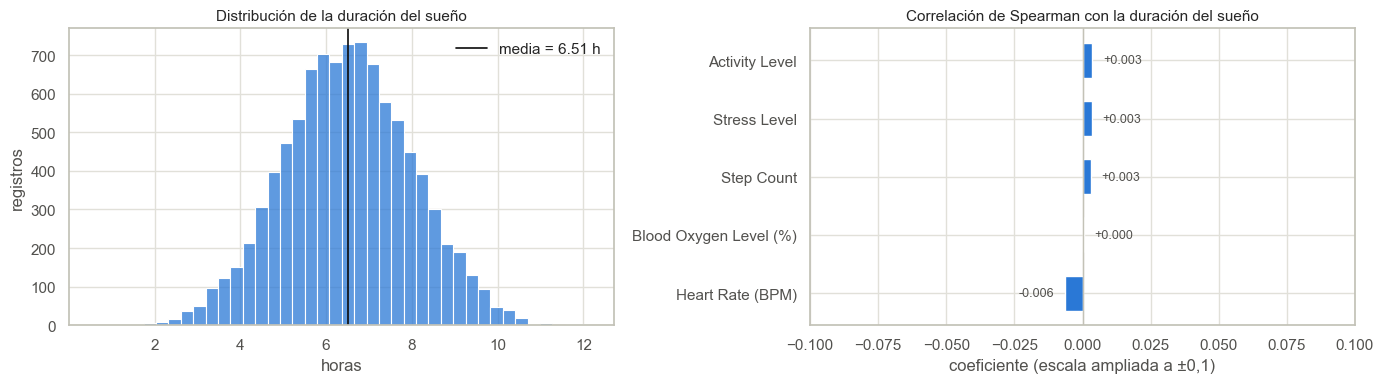

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(y_reg, bins=40, ax=axes[0], color="#2a78d6")
axes[0].axvline(y_reg.mean(), color="#0b0b0b", linewidth=1.2, label=f"media = {y_reg.mean():.2f} h")
axes[0].set_title("Distribución de la duración del sueño")
axes[0].set_xlabel("horas")
axes[0].set_ylabel("registros")
axes[0].legend(frameon=False)

correlaciones = (datos_reg[ENTRADAS_REG + [OBJETIVO_REG]]
                 .assign(**{"Activity Level": datos_reg["Activity Level"].map(
                     {n: i for i, n in enumerate(ORDEN_ACTIVIDAD)})})
                 .corr(method="spearman")[OBJETIVO_REG].drop(OBJETIVO_REG))
correlaciones.sort_values().plot(kind="barh", ax=axes[1], color="#2a78d6", width=0.6)
axes[1].axvline(0, color="#c3c2b7", linewidth=1)
axes[1].set_xlim(-0.1, 0.1)
axes[1].set_title("Correlación de Spearman con la duración del sueño")
axes[1].set_xlabel("coeficiente (escala ampliada a ±0,1)")
for posicion, valor in enumerate(correlaciones.sort_values()):
    axes[1].text(valor + (0.004 if valor >= 0 else -0.004), posicion, f"{valor:+.3f}",
                 va="center", ha="left" if valor >= 0 else "right", fontsize=9, color="#52514e")

plt.tight_layout()
plt.show()

La distribución del objetivo es aproximadamente normal, centrada en unas 6,5 horas, lo que
la hace adecuada para métricas basadas en error cuadrático. El panel derecho anticipa el
problema central: **ninguna variable de entrada tiene una correlación con el sueño mayor a
0,01 en valor absoluto** (el eje está ampliado a ±0,1 para que las barras se vean). Con
relaciones de esta magnitud, ningún modelo lineal podrá explicar una fracción relevante de
la varianza; los modelos no lineales se incluyen para descartar que exista una relación no
monótona que Spearman no capte.

### Partición entrenamiento y prueba

Se reserva el 20 % de los registros como conjunto de prueba. Todo el ajuste de
hiperparámetros se hace con validación cruzada sobre el 80 % restante.

In [7]:
X_reg_ent, X_reg_prueba, y_reg_ent, y_reg_prueba = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=SEMILLA)

CV_REG = KFold(n_splits=5, shuffle=True, random_state=SEMILLA)

print(f"Entrenamiento: {X_reg_ent.shape}  |  Prueba: {X_reg_prueba.shape}")

Entrenamiento: (7681, 5)  |  Prueba: (1921, 5)


### Modelos e hiperparámetros explorados

Se comparan tres algoritmos de naturaleza distinta, más una línea base:

| Modelo | Tipo | Hiperparámetros explorados | Por qué se incluye |
| --- | --- | --- | --- |
| Línea base (`DummyRegressor`) | Trivial | Ninguno: siempre predice la media de entrenamiento | Referencia mínima. Un modelo que no la supera no aprendió nada |
| `Ridge` | Lineal con regularización L2 | `alpha`: fuerza de la regularización | Captura relaciones lineales y controla el sobreajuste penalizando coeficientes grandes |
| `KNeighborsRegressor` | No lineal, basado en distancias | `n_neighbors`, `weights` | Aprende relaciones locales sin asumir una forma funcional; requiere datos escalados |
| `RandomForestRegressor` | No lineal, ensamble de árboles | `max_depth`, `min_samples_leaf` | Captura interacciones y no linealidades; los hiperparámetros controlan la complejidad |

### Métricas de evaluación

| Métrica | Fórmula | Interpretación en este problema |
| --- | --- | --- |
| MSE | $\frac{1}{N}\sum_{i=1}^{N}(y_i-\hat{y}_i)^2$ | Error cuadrático medio, en horas². Penaliza más los errores grandes |
| RMSE | $\sqrt{\text{MSE}}$ | El mismo criterio, pero en horas: es el error típico de una predicción. **Guía la búsqueda de hiperparámetros** |
| MAE | $\frac{1}{N}\sum_{i=1}^{N}\lvert y_i-\hat{y}_i\rvert$ | Error absoluto medio, en horas. Menos sensible a los errores extremos |
| MAPE | $\frac{100\%}{N}\sum_{i=1}^{N}\left\lvert\frac{y_i-\hat{y}_i}{y_i}\right\rvert$ | Error relativo. Se infla cuando $y_i$ es pequeño (hay noches de menos de una hora), por lo que se reporta solo como complemento |
| R² | $1-\frac{\sum(y_i-\hat{y}_i)^2}{\sum(y_i-\bar{y})^2}$ | Fracción de la varianza explicada. 0 equivale a predecir siempre la media; un valor negativo, a hacerlo peor que la media |
| R² ajustado | $1-\frac{N-1}{N-D-1}\,(1-R^2)$ | Corrige el R² por el número de variables de entrada ($D = 5$): solo sube si las variables aportan más de lo que aportarían por azar |

Las métricas de error se calculan en validación cruzada y en el conjunto de prueba. El R²
ajustado se calcula en el conjunto de prueba, donde $N$ es fijo.

In [8]:
METRICAS_REG = {
    "MSE": "neg_mean_squared_error",
    "RMSE": "neg_root_mean_squared_error",
    "MAE": "neg_mean_absolute_error",
    "MAPE": "neg_mean_absolute_percentage_error",
    "R2": "r2",
}

modelos_reg = {
    "Línea base": (DummyRegressor(strategy="mean"), {}),
    "Ridge": (Ridge(), {"modelo__alpha": [0.01, 0.1, 1, 10, 100, 1000]}),
    "KNN": (KNeighborsRegressor(), {
        "modelo__n_neighbors": [5, 25, 75, 150, 300],
        "modelo__weights": ["uniform", "distance"],
    }),
    "Random Forest": (RandomForestRegressor(n_estimators=100, random_state=SEMILLA, n_jobs=1), {
        "modelo__max_depth": [2, 4, 8, 16, None],
        "modelo__min_samples_leaf": [1, 20, 100],
    }),
}

buscadores_reg = {}
for nombre, (modelo, grilla) in modelos_reg.items():
    pipeline = Pipeline([("prep", construir_preprocesador(ENTRADAS_REG)), ("modelo", modelo)])
    buscadores_reg[nombre] = buscar(nombre, pipeline, grilla, X_reg_ent, y_reg_ent,
                                    CV_REG, METRICAS_REG, refit="RMSE")

Línea base                 mejores hiperparámetros: (sin hiperparámetros)


Ridge                      mejores hiperparámetros: {'modelo__alpha': 1000}


KNN                        mejores hiperparámetros: {'modelo__n_neighbors': 300, 'modelo__weights': 'uniform'}


Random Forest              mejores hiperparámetros: {'modelo__max_depth': 2, 'modelo__min_samples_leaf': 20}


### Resultados de la validación cruzada

La tabla muestra, para la mejor configuración de cada modelo, la media de los 5 pliegues
en validación (`CV`), su desviación estándar y el valor en entrenamiento. El MAPE se expresa
en porcentaje.

In [9]:
tabla_cv_reg = resumen_cv(buscadores_reg, ["MSE", "RMSE", "MAE", "MAPE", "R2"],
                          negativas=("MSE", "RMSE", "MAE", "MAPE"))
# scikit-learn entrega el MAPE como fracción; se expresa en porcentaje.
columnas_mape = ["MAPE (CV)", "MAPE desv.", "MAPE (entren.)"]
tabla_cv_reg[columnas_mape] = tabla_cv_reg[columnas_mape] * 100
tabla_cv_reg[["RMSE (CV)", "RMSE desv.", "MAE (CV)", "MSE (CV)", "MAPE (CV)",
              "R2 (CV)", "R2 desv.", "R2 (entren.)"]]

,RMSE (CV),RMSE desv.,MAE (CV),MSE (CV),MAPE (CV),R2 (CV),R2 desv.,R2 (entren.)
modelo,,,,,,,,
Línea base,1.5064,0.0193,1.2091,2.2695,21.0785,-0.0025,0.0018,0.0000
Ridge,1.5072,0.0194,1.2097,2.2720,21.0885,-0.0036,0.0017,0.0002
KNN,1.5090,0.0195,1.2113,2.2774,21.1184,-0.0060,0.0013,0.0020
Random Forest,1.5085,0.0195,1.2111,2.2761,21.1170,-0.0054,0.0016,0.0050


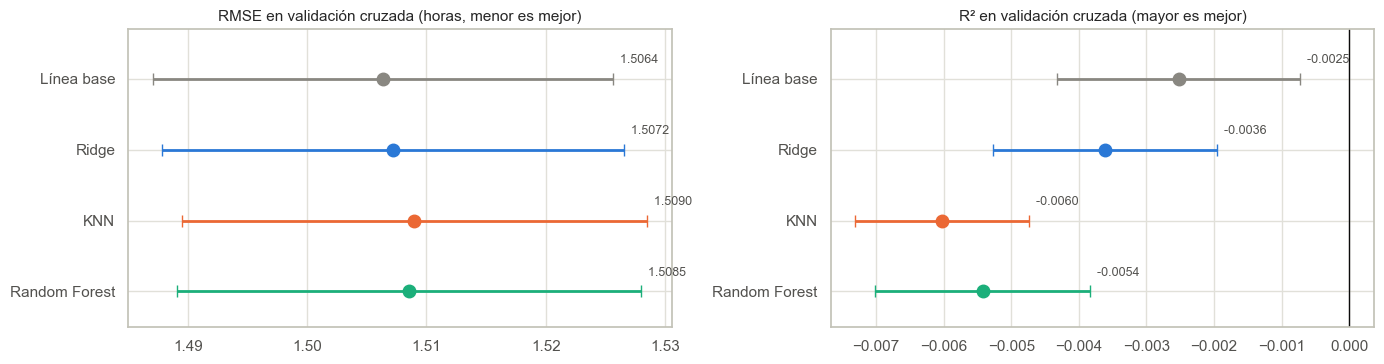

In [10]:
# Puntos con barras de error (± 1 desviación entre pliegues): las diferencias entre
# modelos son tan pequeñas que un gráfico de barras desde cero las haría invisibles.
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
nombres = list(buscadores_reg)

for ax, metrica, titulo in [(axes[0], "RMSE", "RMSE en validación cruzada (horas, menor es mejor)"),
                            (axes[1], "R2", "R² en validación cruzada (mayor es mejor)")]:
    for posicion, nombre in enumerate(nombres):
        media = tabla_cv_reg.loc[nombre, f"{metrica} (CV)"]
        desv = tabla_cv_reg.loc[nombre, f"{metrica} desv."]
        ax.errorbar(media, posicion, xerr=desv, fmt="o", markersize=9, color=COLORES[nombre],
                    ecolor=COLORES[nombre], elinewidth=2, capsize=4)
        ax.text(media + desv, posicion - 0.22, f"  {media:.4f}", fontsize=9, color="#52514e")
    ax.set_yticks(range(len(nombres)), nombres)
    ax.set_ylim(len(nombres) - 0.5, -0.7)
    ax.set_title(titulo)

axes[1].axvline(0, color="#0b0b0b", linewidth=1)
plt.tight_layout()
plt.show()

**Lectura de los resultados**

- **Ningún modelo supera a la línea base.** El RMSE de todos los modelos es igual o mayor
  que el de predecir siempre la media, y su R² en validación es cercano a cero o negativo.
  Un R² negativo significa que el modelo comete más error que la media constante.
- **La diferencia entre modelos está dentro del ruido.** Las diferencias de RMSE entre la
  línea base y Ridge son menores que la desviación estándar entre pliegues.
- **La búsqueda de hiperparámetros empuja a todos los modelos hacia la predicción
  constante:** Ridge elige la regularización más fuerte (coeficientes casi nulos), KNN el
  mayor número de vecinos (promedia casi todo el conjunto) y Random Forest los árboles
  menos profundos. Es la respuesta correcta del procedimiento cuando no hay señal: la mejor
  forma de no equivocarse es no intentar predecir.
- **Los óptimos quedan en el extremo de menor complejidad de cada grilla, y la búsqueda no
  se amplió a propósito.** El límite de ese extremo es la propia línea base: Ridge con un
  `alpha` muy grande anula los coeficientes y predice la media de entrenamiento; KNN con
  tantos vecinos como registros de entrenamiento promedia todo el conjunto y también predice
  la media; y un árbol sin divisiones hace lo mismo. Ampliar la grilla en esa dirección solo
  acercaría a los modelos a la línea base, cuyo desempeño ya figura en la tabla.

### Exploración de hiperparámetros: complejidad y sobreajuste

La grilla de Random Forest permite observar cómo cambia el desempeño al aumentar la
profundidad de los árboles. Se grafica el R² en entrenamiento y en validación para cada
`max_depth`, con `min_samples_leaf = 1` (hojas de un solo registro), que es la
configuración donde el efecto de la profundidad se ve sin otra restricción.

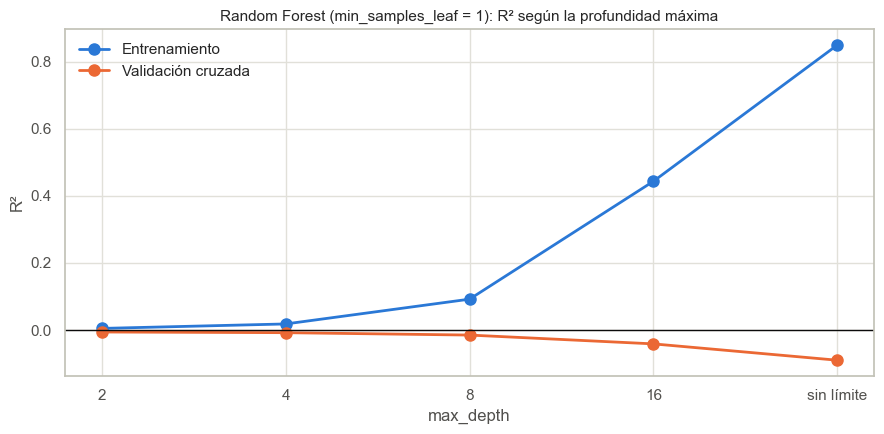

,mean_train_R2,mean_test_R2
profundidad,,
2,0.0052,-0.0055
4,0.0185,-0.0075
8,0.0923,-0.0146
16,0.4433,-0.0409
sin límite,0.8489,-0.0895


In [11]:
resultados_rf = pd.DataFrame(buscadores_reg["Random Forest"].cv_results_)
resultados_rf["profundidad"] = resultados_rf["param_modelo__max_depth"].astype(object).fillna("sin límite").astype(str)
orden = ["2", "4", "8", "16", "sin límite"]
mejor_por_prof = (resultados_rf[resultados_rf["param_modelo__min_samples_leaf"] == 1]
                  .set_index("profundidad").loc[orden])

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(orden, mejor_por_prof["mean_train_R2"], marker="o", markersize=8, linewidth=2,
        color="#2a78d6", label="Entrenamiento")
ax.plot(orden, mejor_por_prof["mean_test_R2"], marker="o", markersize=8, linewidth=2,
        color="#eb6834", label="Validación cruzada")
ax.axhline(0, color="#0b0b0b", linewidth=1)
ax.set_title("Random Forest (min_samples_leaf = 1): R² según la profundidad máxima")
ax.set_xlabel("max_depth")
ax.set_ylabel("R²")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

mejor_por_prof[["mean_train_R2", "mean_test_R2"]]

El gráfico es la definición de **sobreajuste**: a medida que los árboles se vuelven más
profundos, el R² de entrenamiento sube con fuerza (el bosque memoriza los registros),
mientras que el de validación se mantiene en cero o empeora. Lo que el modelo "aprende" con
más profundidad es el ruido particular de cada registro, que no se repite en datos nuevos.

La grilla de KNN muestra el mismo fenómeno desde otro hiperparámetro. Con pocos vecinos, la
predicción copia a los registros de entrenamiento más cercanos; con pesos por distancia
(`weights="distance"`), cada registro de entrenamiento es su propio vecino a distancia cero
y se predice a sí mismo. La tabla compara el R² de entrenamiento y de validación para cada
combinación.

In [12]:
complejidad_knn = (pd.DataFrame(buscadores_reg["KNN"].cv_results_)
                   .rename(columns={"param_modelo__weights": "weights",
                                    "param_modelo__n_neighbors": "n_neighbors",
                                    "mean_train_R2": "R² entrenamiento",
                                    "mean_test_R2": "R² validación"})
                   .set_index(["weights", "n_neighbors"])
                   [["R² entrenamiento", "R² validación"]]
                   .sort_index())
complejidad_knn

R² entrenamiento  R² validación
weights  n_neighbors                                 
distance 5                      1.0000        -0.2262
         25                     1.0000        -0.0537
         75                     1.0000        -0.0174
         150                    1.0000        -0.0093
         300                    1.0000        -0.0065
uniform  5                      0.1998        -0.2069
         25                     0.0358        -0.0470
         75                     0.0146        -0.0142
         150                    0.0069        -0.0078
         300                    0.0020        -0.0060

Con pesos por distancia, el R² de entrenamiento es 1 para cualquier número de vecinos; con
5 vecinos y pesos uniformes llega a 0,20. En validación, en cambio, esas mismas
configuraciones caen a −0,23 y −0,21: el modelo memoriza el entrenamiento y empeora con
datos nuevos. A medida que aumenta el número de vecinos, la brecha se cierra y el R² de
validación se acerca a cero, que es el valor de la línea base.

### Evaluación en el conjunto de prueba

Cada modelo, con su mejor configuración, se evalúa una única vez sobre el 20 % reservado.

In [13]:
N_ENTRADAS_REG = len(ENTRADAS_REG)


def metricas_regresion(y_real, y_pred, d=N_ENTRADAS_REG):
    n = len(y_real)
    r2 = r2_score(y_real, y_pred)
    return {
        "MSE": mean_squared_error(y_real, y_pred),
        "RMSE": root_mean_squared_error(y_real, y_pred),
        "MAE": mean_absolute_error(y_real, y_pred),
        "MAPE (%)": 100 * mean_absolute_percentage_error(y_real, y_pred),
        "R2": r2,
        "R2 ajustado": 1 - (1 - r2) * (n - 1) / (n - d - 1),
    }


predicciones_reg = {n: b.best_estimator_.predict(X_reg_prueba) for n, b in buscadores_reg.items()}
tabla_prueba_reg = pd.DataFrame({n: metricas_regresion(y_reg_prueba, p)
                                 for n, p in predicciones_reg.items()}).T
tabla_prueba_reg

,MSE,RMSE,MAE,MAPE (%),R2,R2 ajustado
Línea base,2.3086,1.5194,1.2051,21.6663,-0.0017,-0.0044
Ridge,2.3088,1.5195,1.2052,21.6666,-0.0018,-0.0044
KNN,2.3085,1.5194,1.2056,21.6782,-0.0017,-0.0043
Random Forest,2.3104,1.5200,1.2056,21.6684,-0.0025,-0.0051


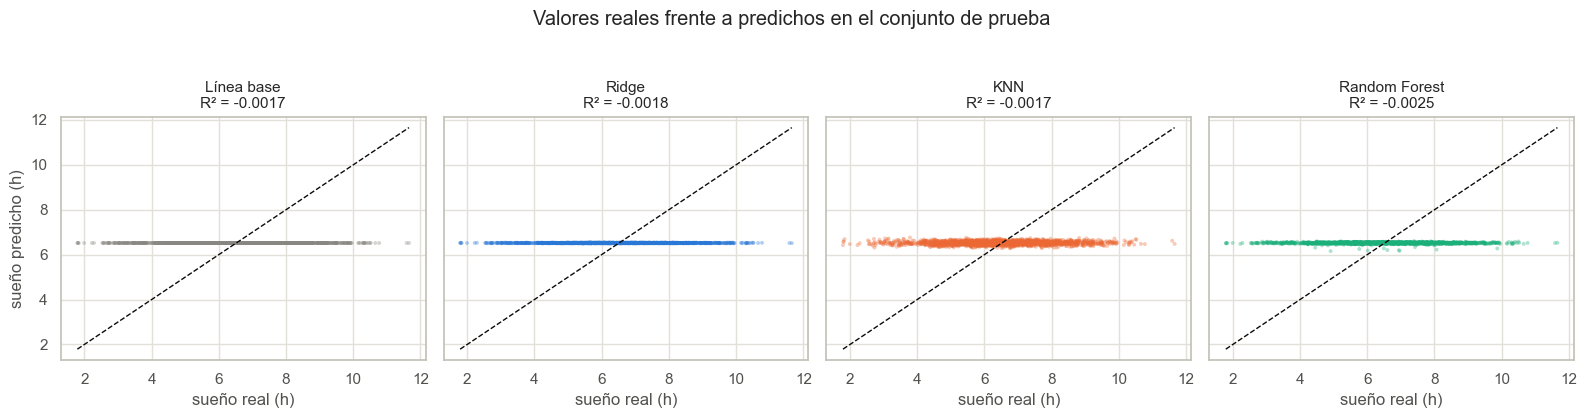

In [14]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharex=True, sharey=True)
limites = (y_reg_prueba.min(), y_reg_prueba.max())

for ax, (nombre, pred) in zip(axes, predicciones_reg.items()):
    ax.scatter(y_reg_prueba, pred, s=8, alpha=0.35, color=COLORES[nombre], edgecolor="none")
    ax.plot(limites, limites, color="#0b0b0b", linewidth=1, linestyle="--")
    ax.set_title(f"{nombre}\nR² = {r2_score(y_reg_prueba, pred):.4f}")
    ax.set_xlabel("sueño real (h)")
axes[0].set_ylabel("sueño predicho (h)")
fig.suptitle("Valores reales frente a predichos en el conjunto de prueba", y=1.04)
plt.tight_layout()
plt.show()

Si un modelo predijera bien, los puntos se alinearían con la diagonal punteada. En los
cuatro paneles las predicciones forman una franja horizontal angosta alrededor de 6,5
horas: **cualquiera sea el registro, el modelo predice aproximadamente lo mismo**. En la
tabla, las diferencias entre modelos son de milésimas de hora en el RMSE. Además, el orden
cambia: KNN, que era el último en validación cruzada, empata en prueba con la línea base
(RMSE de 1,5194), lo que confirma que el orden entre ellos es ruido. El resultado en prueba
coincide con el de la validación cruzada, por lo que no se trata de una partición
desafortunada.

Las métricas complementarias llevan a la misma conclusión. El MAPE ronda el 21,7 % en los
cuatro casos, igual que el de la línea base, y el R² ajustado (≈ −0,004) queda todavía más
abajo que el R², porque descuenta las cinco variables de entrada sin aportarles nada a
cambio.

### Control positivo: ¿el procedimiento es capaz de encontrar señal?

Un R² cercano a cero puede deberse a dos causas: que los datos no tengan relación o que el
procedimiento esté mal construido. Para descartar la segunda, se crea un **objetivo
sintético** que sí depende de las variables de entrada (una combinación del pulso y los
pasos más ruido aleatorio) y se entrena con exactamente el mismo pipeline.

In [15]:
rng = np.random.default_rng(SEMILLA)
pulso_z = (X_reg_ent["Heart Rate (BPM)"] - X_reg_ent["Heart Rate (BPM)"].mean()) / X_reg_ent["Heart Rate (BPM)"].std()
pasos_z = (X_reg_ent["Step Count"] - X_reg_ent["Step Count"].mean()) / X_reg_ent["Step Count"].std()
y_sintetico = (6.5 + 0.6 * pulso_z.fillna(0) - 0.4 * pasos_z.fillna(0)
               + rng.normal(0, 0.6, len(X_reg_ent)))

for nombre in ["Ridge", "Random Forest"]:
    control = buscadores_reg[nombre].best_estimator_
    r2 = GridSearchCV(control, [{}], cv=CV_REG, scoring="r2").fit(X_reg_ent, y_sintetico).best_score_
    print(f"{nombre:<14} R² en validación cruzada con objetivo sintético: {r2:.3f}")

Ridge          R² en validación cruzada con objetivo sintético: 0.576


Random Forest  R² en validación cruzada con objetivo sintético: 0.443


Con un objetivo que sí depende de las entradas, el mismo pipeline alcanza un R² cercano a
0,58 con Ridge, prácticamente el máximo posible para ese objetivo (la varianza del ruido
agregado limita el R² teórico a ≈ 0,59), y cercano a 0,44 con Random Forest. **El procedimiento funciona; lo que falta es relación en los datos
reales.**

### Conclusión parcial de regresión

La duración del sueño no puede predecirse a partir de las demás mediciones de este
conjunto. Los cuatro modelos, optimizados con validación cruzada, quedan al nivel de la
predicción constante (R² ≈ 0) tanto en validación como en prueba.

---

## 3. Modelamiento de clasificación

### Objetivo de clasificación

Se define la variable binaria **`estres_alto`**:

- **1 (estrés alto):** `Stress Level` igual o mayor a 7, o el texto `"Very High"`.
- **0 (estrés no alto):** `Stress Level` entre 1 y 6.

En la EP1 el texto `"Very High"` se convirtió en valor faltante, porque no tenía un número
asociado. Para esta etiqueta binaria, en cambio, su significado es inequívoco (es estrés
alto), por lo que esos 49 registros se recuperan como clase 1. El tratamiento es coherente con el
de la regresión: allí el estrés es una variable de entrada numérica, y `"Very High"` no
indica un nivel exacto (podría ser 7, 8, 9 o 10), por lo que se trata como faltante; para
la etiqueta binaria, en cambio, solo importa si el nivel es 7 o más, y eso sí es seguro. Los registros sin nivel de
estrés se excluyen, por la misma razón expuesta en regresión: no se entrena con respuestas
imputadas.

El umbral de 7 corresponde al 30 % superior de la escala 1 a 10 y se elige porque una alerta
preventiva solo tiene sentido para los niveles más altos.

In [16]:
estres_numerico = pd.to_numeric(estres_original, errors="coerce")
estres_alto = pd.Series(np.nan, index=datos.index)
estres_alto[estres_numerico < 7] = 0
estres_alto[estres_numerico >= 7] = 1
estres_alto[estres_original == "Very High"] = 1

ENTRADAS_CLF = ["Heart Rate (BPM)", "Blood Oxygen Level (%)", "Step Count",
                "Sleep Duration (hours)", "Activity Level"]

mascara = estres_alto.notna()
X_clf = datos.loc[mascara, ENTRADAS_CLF]
y_clf = estres_alto[mascara].astype(int)

print(f"Registros con etiqueta: {len(y_clf)} ({(~mascara).sum()} excluidos por estrés faltante)")

Registros con etiqueta: 9800 (200 excluidos por estrés faltante)


### Verificación del desbalance de clases

,registros,proporción
estres_alto,,
0,5898,0.6018
1,3902,0.3982


Razón de desbalance (mayoritaria / minoritaria): 1.51 : 1


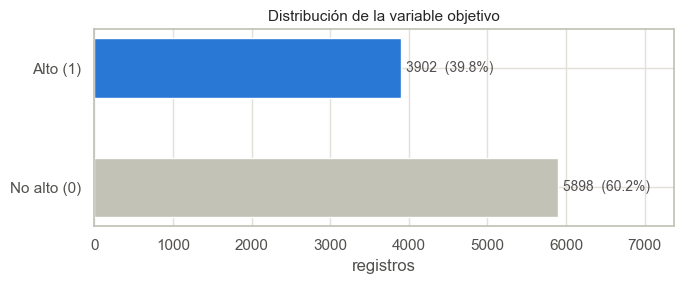

In [17]:
conteo = y_clf.value_counts().sort_index()
proporcion = y_clf.value_counts(normalize=True).sort_index()
razon = conteo.max() / conteo.min()

display(pd.DataFrame({"registros": conteo, "proporción": proporcion},
                     index=pd.Index([0, 1], name="estres_alto")))
print(f"Razón de desbalance (mayoritaria / minoritaria): {razon:.2f} : 1")

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(["No alto (0)", "Alto (1)"], conteo.values, color=["#c3c2b7", "#2a78d6"], height=0.5)
for posicion, (n, p) in enumerate(zip(conteo.values, proporcion.values)):
    ax.text(n + 60, posicion, f"{n}  ({p:.1%})", va="center", fontsize=10, color="#52514e")
ax.set_xlim(0, conteo.max() * 1.25)
ax.set_title("Distribución de la variable objetivo")
ax.set_xlabel("registros")
plt.tight_layout()
plt.show()

**Existe un desbalance moderado**: aproximadamente 60 % de la clase 0 frente a 40 % de la
clase 1 (razón cercana a 1,5 : 1). No es extremo, pero sí suficiente para que un
clasificador sin corrección tienda a favorecer la clase mayoritaria. Un modelo que siempre
responda "no alto" obtendría cerca de 60 % de *accuracy* sin detectar a ningún usuario con
estrés alto, que es justamente el caso que interesa.

Por esto:

1. La métrica principal es el **F1 de la clase 1**, que combina *precision* (de las
   alertas enviadas, cuántas eran correctas) y *recall* (de los usuarios con estrés alto,
   cuántos se detectaron). También se reportan *balanced accuracy* y **ROC AUC**, que no
   dependen de la proporción de clases. La *accuracy* se muestra solo como referencia.
2. Se evalúan técnicas de balanceo antes de elegir una.

### Métricas de evaluación

La clase positiva es **1 (estrés alto)**, que es el caso que la alerta debe detectar. Con VP,
FP, FN y VN se denotan los verdaderos positivos, falsos positivos, falsos negativos y
verdaderos negativos de la matriz de confusión.

| Métrica | Fórmula | Qué responde en este problema |
| --- | --- | --- |
| Matriz de confusión | VP, FP, FN, VN | Cuántos usuarios de cada clase real recibieron (o no) una alerta |
| Accuracy | $\frac{VP+VN}{VP+VN+FP+FN}$ | Fracción de aciertos totales. Engañosa con clases desbalanceadas |
| Precision | $\frac{VP}{VP+FP}$ | De las alertas enviadas, cuántas llegaron a usuarios con estrés alto |
| Recall (sensibilidad) | $\frac{VP}{VP+FN}$ | De los usuarios con estrés alto, cuántos recibieron la alerta |
| F1 | $\frac{2\cdot\text{Precision}\cdot\text{Recall}}{\text{Precision}+\text{Recall}}$ | Media armónica de precision y recall. **Guía la búsqueda de hiperparámetros** |
| Balanced accuracy | $\frac{1}{2}\left(\frac{VP}{VP+FN}+\frac{VN}{VN+FP}\right)$ | Accuracy corregida por el desbalance: 0,5 equivale al azar |
| ROC AUC | Área bajo la curva ROC | Probabilidad de que el modelo asigne más riesgo a un usuario con estrés alto que a uno sin él, sin depender del umbral de decisión: 0,5 equivale al azar |

### Partición estratificada

In [18]:
X_clf_ent, X_clf_prueba, y_clf_ent, y_clf_prueba = train_test_split(
    X_clf, y_clf, test_size=0.2, stratify=y_clf, random_state=SEMILLA)

CV_CLF = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

print(f"Entrenamiento: {X_clf_ent.shape}, proporción clase 1 = {y_clf_ent.mean():.3f}")
print(f"Prueba:        {X_clf_prueba.shape}, proporción clase 1 = {y_clf_prueba.mean():.3f}")

Entrenamiento: (7840, 5), proporción clase 1 = 0.398
Prueba:        (1960, 5), proporción clase 1 = 0.398


La partición estratificada mantiene la misma proporción de clases en entrenamiento y
prueba, y `StratifiedKFold` hace lo mismo en cada pliegue de la validación cruzada.

### Comparación de técnicas de balanceo

Se comparan cuatro estrategias sobre una regresión logística (modelo rápido y sensible al
desbalance), con validación cruzada:

| Estrategia | Cómo funciona |
| --- | --- |
| Sin balanceo | Se entrena con la proporción original |
| `class_weight="balanced"` | Penaliza más los errores en la clase minoritaria, sin modificar los datos |
| `SMOTE` | Genera registros sintéticos de la clase minoritaria interpolando entre vecinos |
| Submuestreo aleatorio | Descarta registros de la clase mayoritaria hasta igualar ambas clases |

El sobremuestreo y el submuestreo se aplican **dentro del pipeline de `imbalanced-learn`**,
por lo que solo actúan sobre los pliegues de entrenamiento. Los pliegues de validación
conservan la distribución real: si SMOTE se aplicara antes de dividir, los registros
sintéticos contaminarían la validación.

In [19]:
METRICAS_CLF = {
    "Accuracy": "accuracy",
    "Balanced acc.": "balanced_accuracy",
    # zero_division=0: un modelo que nunca predice la clase 1 tiene precision 0 (sin advertencias).
    "Precision": make_scorer(precision_score, zero_division=0),
    "Recall": "recall",
    "F1": "f1",
    "ROC AUC": "roc_auc",
}

estrategias = {
    "Sin balanceo": ("passthrough", LogisticRegression(max_iter=1000)),
    "class_weight='balanced'": ("passthrough", LogisticRegression(max_iter=1000, class_weight="balanced")),
    "SMOTE": (SMOTE(random_state=SEMILLA), LogisticRegression(max_iter=1000)),
    "Submuestreo aleatorio": (RandomUnderSampler(random_state=SEMILLA), LogisticRegression(max_iter=1000)),
}

buscadores_balanceo = {}
for nombre, (balanceo, modelo) in estrategias.items():
    pipeline = ImbPipeline([("prep", construir_preprocesador(ENTRADAS_CLF)),
                            ("balanceo", balanceo), ("modelo", modelo)])
    buscadores_balanceo[nombre] = GridSearchCV(pipeline, [{}], cv=CV_CLF, scoring=METRICAS_CLF,
                                               refit="F1", return_train_score=True,
                                               n_jobs=-1).fit(X_clf_ent, y_clf_ent)

tabla_balanceo = resumen_cv(buscadores_balanceo, list(METRICAS_CLF))
tabla_balanceo[[f"{m} (CV)" for m in METRICAS_CLF]]

,Accuracy (CV),Balanced acc. (CV),Precision (CV),Recall (CV),F1 (CV),ROC AUC (CV)
modelo,,,,,,
Sin balanceo,0.6018,0.5000,0.0000,0.0000,0.0000,0.4810
class_weight='balanced',0.4899,0.4868,0.3854,0.4715,0.4241,0.4812
SMOTE,0.4901,0.4864,0.3846,0.4686,0.4223,0.4804
Submuestreo aleatorio,0.4917,0.4918,0.3903,0.4920,0.4353,0.4852


**Decisión: se usa SMOTE en todos los clasificadores.**

- **Sin balanceo** el modelo se refugia en la clase mayoritaria: su *accuracy* parece
  aceptable (cerca de 0,60), pero el *recall* y el F1 de la clase 1 son prácticamente cero.
  Es el ejemplo de por qué la *accuracy* engaña con clases desbalanceadas.
- Las tres técnicas de balanceo recuperan el *recall* (≈ 0,47 a 0,49) y el F1 de la clase 1
  (≈ 0,42 a 0,44). Las diferencias entre ellas son menores que la desviación estándar entre
  pliegues, por lo que en este problema son equivalentes. Ninguna mejora la *balanced
  accuracy* ni el AUC (ambos ≈ 0,48 a 0,49), porque no hay señal que recuperar, pero cumplen
  su función: el modelo deja de ignorar la clase minoritaria.
- Entre ellas se elige **SMOTE** porque es la única que se puede aplicar a **los cuatro
  algoritmos por igual** sin perder datos. `KNeighborsClassifier` no admite
  `class_weight`, y el submuestreo, aunque obtiene un F1 levemente mayor, descarta en cada
  pliegue cerca de 1.280 registros de la clase 0, un tercio de esa clase. Usar
  la misma técnica en todos los modelos mantiene la comparación justa.

### Modelos e hiperparámetros explorados

Se comparan cuatro algoritmos distintos, más dos líneas base:

| Modelo | Hiperparámetros explorados | Por qué se incluye |
| --- | --- | --- |
| Línea base (azar) | Ninguno: predice al azar respetando la proporción de clases | Referencia para F1 y AUC |
| Línea base (mayoritaria) | Ninguno: siempre predice la clase 0 | Muestra el techo engañoso de la *accuracy* |
| Regresión logística | `C` (inverso de la regularización) | Modelo lineal e interpretable |
| KNN | `n_neighbors`, `weights` | No lineal, basado en distancias |
| Árbol de decisión | `max_depth`, `min_samples_leaf` | No lineal, reglas interpretables |
| **Random Forest** | `n_estimators`, `max_depth`, `min_samples_leaf`, `max_features` | **Modelo optimizado en profundidad**: es el más flexible y el que más depende de sus hiperparámetros |

La búsqueda se guía por el **F1 de la clase 1**.

In [20]:
modelos_clf = {
    "Línea base (azar)": (DummyClassifier(strategy="stratified", random_state=SEMILLA), {}),
    "Línea base (mayoritaria)": (DummyClassifier(strategy="most_frequent"), {}),
    "Regresión logística": (LogisticRegression(max_iter=1000), {
        "modelo__C": [0.001, 0.01, 0.1, 1, 10],
    }),
    "KNN": (KNeighborsClassifier(), {
        "modelo__n_neighbors": [5, 25, 75, 150],
        "modelo__weights": ["uniform", "distance"],
    }),
    "Árbol de decisión": (DecisionTreeClassifier(random_state=SEMILLA), {
        "modelo__max_depth": [3, 5, 10, None],
        "modelo__min_samples_leaf": [1, 20, 100],
    }),
    "Random Forest": (RandomForestClassifier(random_state=SEMILLA, n_jobs=1), {
        "modelo__n_estimators": [100, 200],
        "modelo__max_depth": [4, 8, 16, None],
        "modelo__min_samples_leaf": [1, 20],
        "modelo__max_features": ["sqrt", None],
    }),
}

buscadores_clf = {}
for nombre, (modelo, grilla) in modelos_clf.items():
    # Las líneas base no aprenden de los datos, así que no se les aplica balanceo.
    balanceo = "passthrough" if nombre.startswith("Línea base") else SMOTE(random_state=SEMILLA)
    pipeline = ImbPipeline([("prep", construir_preprocesador(ENTRADAS_CLF)),
                            ("balanceo", balanceo), ("modelo", modelo)])
    buscadores_clf[nombre] = buscar(nombre, pipeline, grilla, X_clf_ent, y_clf_ent,
                                    CV_CLF, METRICAS_CLF, refit="F1")

Línea base (azar)          mejores hiperparámetros: (sin hiperparámetros)
Línea base (mayoritaria)   mejores hiperparámetros: (sin hiperparámetros)


Regresión logística        mejores hiperparámetros: {'modelo__C': 0.1}


KNN                        mejores hiperparámetros: {'modelo__n_neighbors': 75, 'modelo__weights': 'uniform'}


Árbol de decisión          mejores hiperparámetros: {'modelo__max_depth': 3, 'modelo__min_samples_leaf': 1}


Random Forest              mejores hiperparámetros: {'modelo__max_depth': 4, 'modelo__max_features': 'sqrt', 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 100}


### Optimización del Random Forest

La grilla del Random Forest tiene 32 combinaciones (160 entrenamientos con 5 pliegues). El
mapa de calor muestra el F1 en validación según la profundidad y el número de variables
consideradas en cada división, con el mejor valor de los otros dos hiperparámetros. El
gráfico de la derecha compara entrenamiento y validación según la profundidad.

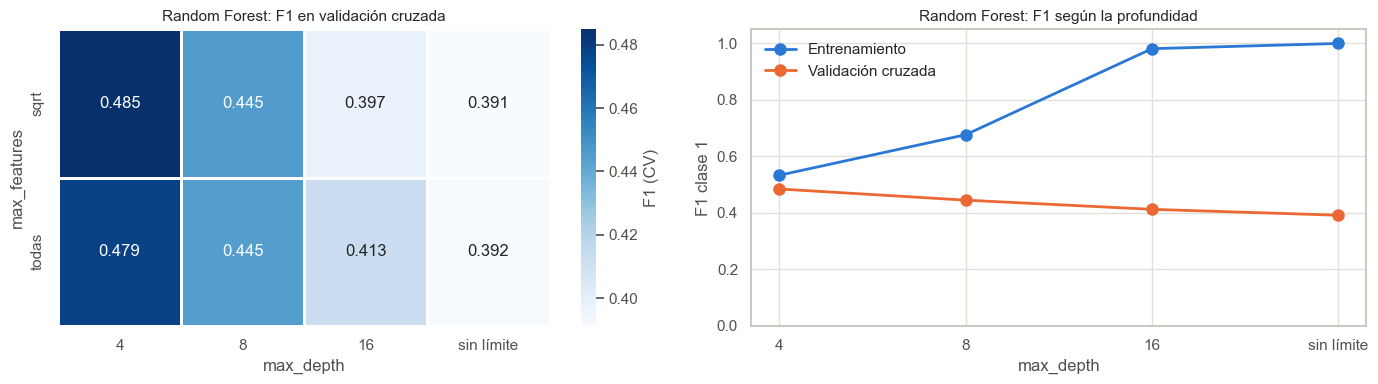

Mejor configuración: {'modelo__max_depth': 4, 'modelo__max_features': 'sqrt', 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 100}


,mean_train_F1,mean_test_F1
max_depth,,
4,0.5330,0.4850
8,0.6770,0.4450
16,0.9820,0.4130
sin límite,1.0000,0.3920


In [21]:
res_rf = pd.DataFrame(buscadores_clf["Random Forest"].cv_results_)
res_rf["max_depth"] = res_rf["param_modelo__max_depth"].astype(object).fillna("sin límite").astype(str)
res_rf["max_features"] = res_rf["param_modelo__max_features"].astype(object).fillna("todas").astype(str)
orden_prof = ["4", "8", "16", "sin límite"]

mapa = (res_rf.groupby(["max_features", "max_depth"])["mean_test_F1"].max()
        .unstack()[orden_prof])
curva = res_rf.groupby("max_depth")[["mean_train_F1", "mean_test_F1"]].max().loc[orden_prof]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.heatmap(mapa, annot=True, fmt=".3f", cmap="Blues", cbar_kws={"label": "F1 (CV)"},
            linewidths=2, linecolor="white", ax=axes[0])
axes[0].set_title("Random Forest: F1 en validación cruzada")
axes[0].set_xlabel("max_depth")
axes[0].set_ylabel("max_features")

axes[1].plot(orden_prof, curva["mean_train_F1"], marker="o", markersize=8, linewidth=2,
             color="#2a78d6", label="Entrenamiento")
axes[1].plot(orden_prof, curva["mean_test_F1"], marker="o", markersize=8, linewidth=2,
             color="#eb6834", label="Validación cruzada")
axes[1].set_ylim(0, 1.05)
axes[1].set_title("Random Forest: F1 según la profundidad")
axes[1].set_xlabel("max_depth")
axes[1].set_ylabel("F1 clase 1")
axes[1].legend(frameon=False)
plt.tight_layout()
plt.show()

print("Mejor configuración:", buscadores_clf["Random Forest"].best_params_)
curva.round(3)

El mapa de calor muestra que el F1 en validación **baja a medida que los árboles son más
profundos**, mientras que `max_features` casi no influye. La mejor combinación es la más
restringida de la grilla (profundidad 4); no se exploraron profundidades menores porque,
como en regresión, el límite de esa dirección es un modelo constante, equivalente a las
líneas base ya evaluadas. El gráfico de la derecha repite el patrón visto en
regresión: con árboles profundos el F1 de entrenamiento
llega casi a 1 (el bosque memoriza los datos, incluidos los registros sintéticos de SMOTE),
mientras que el de validación baja de ≈ 0,49 a ≈ 0,39. **Más complejidad solo produce más sobreajuste.**

### Resultados de la validación cruzada

In [22]:
tabla_cv_clf = resumen_cv(buscadores_clf, list(METRICAS_CLF))
tabla_cv_clf[["F1 (CV)", "F1 desv.", "Recall (CV)", "Precision (CV)",
              "Balanced acc. (CV)", "ROC AUC (CV)", "Accuracy (CV)", "F1 (entren.)"]]

,F1 (CV),F1 desv.,Recall (CV),Precision (CV),Balanced acc. (CV),ROC AUC (CV),Accuracy (CV),F1 (entren.)
modelo,,,,,,,,
Línea base (azar),0.4005,0.0069,0.4042,0.3969,0.4989,0.4989,0.5181,0.3952
Línea base (mayoritaria),0.0000,0.0000,0.0000,0.0000,0.5000,0.5000,0.6018,0.0000
Regresión logística,0.4226,0.0179,0.4693,0.3846,0.4864,0.4804,0.4899,0.4446
KNN,0.4394,0.0087,0.5083,0.3870,0.4878,0.4863,0.4837,0.4965
Árbol de decisión,0.5031,0.0857,0.7408,0.3912,0.4983,0.4984,0.4490,0.5200
Random Forest,0.4849,0.0419,0.6316,0.3977,0.5005,0.4979,0.4739,0.5335


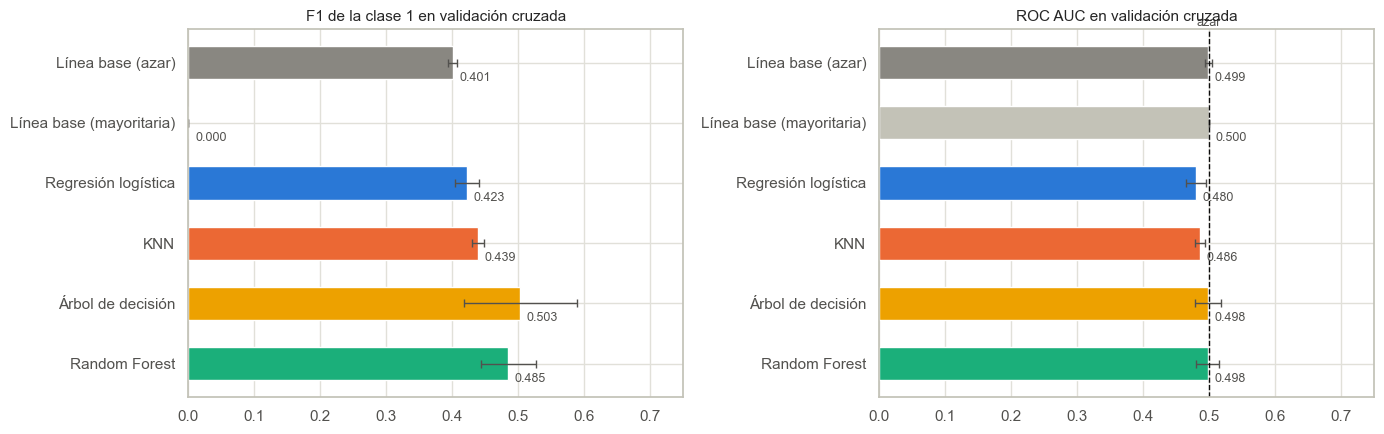

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
nombres = list(buscadores_clf)
colores = [COLORES[n] for n in nombres]

for ax, metrica, titulo, referencia in [
        (axes[0], "F1", "F1 de la clase 1 en validación cruzada", None),
        (axes[1], "ROC AUC", "ROC AUC en validación cruzada", 0.5)]:
    medias = tabla_cv_clf[f"{metrica} (CV)"]
    desv = tabla_cv_clf[f"{metrica} desv."]
    ax.barh(nombres, medias, xerr=desv, color=colores, height=0.55,
            error_kw={"ecolor": "#52514e", "capsize": 3, "linewidth": 1})
    if referencia is not None:
        ax.axvline(referencia, color="#0b0b0b", linewidth=1, linestyle="--")
        ax.text(referencia, 1.01, "azar", transform=ax.get_xaxis_transform(),
                ha="center", fontsize=9, color="#52514e")
    for posicion, valor in enumerate(medias):
        ax.text(valor + 0.01, posicion + 0.3, f"{valor:.3f}", fontsize=9, color="#52514e")
    ax.set_xlim(0, max(0.75, medias.max() + 0.1))
    ax.set_title(titulo)
    ax.invert_yaxis()

plt.tight_layout()
plt.show()

**Lectura de los resultados**

- **Todos los modelos entrenados tienen un AUC entre 0,48 y 0,50 en validación**, el mismo
  nivel de la línea base al azar: ninguno ordena mejor que una moneda a los usuarios según
  su probabilidad de estrés alto.
- **Los F1 de los modelos se explican por cuánto predicen la clase 1, no por lo que
  aprendieron.** Con SMOTE los modelos marcan como positivos a una fracción grande de los
  usuarios; eso sube el *recall* y fija la *precision* en torno a 0,40, que es la
  proporción real de la clase 1. El árbol de decisión tiene el F1 más alto (≈ 0,50) porque
  es el que más usuarios marca como positivos (*recall* ≈ 0,74), no porque acierte más. Un
  modelo que marcara a **todos** como estrés alto obtendría F1 = 2·0,40·1 / (0,40 + 1) ≈ 0,57
  sin usar ningún dato.
- La **línea base mayoritaria** tiene la mejor *accuracy* (≈ 0,60) y F1 = 0: confirma que
  la *accuracy* no sirve para este problema.

### Evaluación en el conjunto de prueba

In [24]:
def metricas_clasificacion(modelo, X, y):
    pred = modelo.predict(X)
    prob = modelo.predict_proba(X)[:, 1]
    return {
        "Accuracy": accuracy_score(y, pred),
        "Balanced acc.": balanced_accuracy_score(y, pred),
        "Precision": precision_score(y, pred, zero_division=0),
        "Recall": recall_score(y, pred),
        "F1": f1_score(y, pred),
        "ROC AUC": roc_auc_score(y, prob),
    }


mejores_clf = {n: b.best_estimator_ for n, b in buscadores_clf.items()}
tabla_prueba_clf = pd.DataFrame({n: metricas_clasificacion(m, X_clf_prueba, y_clf_prueba)
                                 for n, m in mejores_clf.items()}).T
tabla_prueba_clf

,Accuracy,Balanced acc.,Precision,Recall,F1,ROC AUC
Línea base (azar),0.5056,0.4862,0.3817,0.3910,0.3863,0.4862
Línea base (mayoritaria),0.6020,0.5000,0.0000,0.0000,0.0000,0.5000
Regresión logística,0.4995,0.4978,0.3959,0.4897,0.4378,0.4893
KNN,0.5128,0.5165,0.4133,0.5346,0.4662,0.5142
Árbol de decisión,0.4219,0.4910,0.3928,0.8295,0.5332,0.4914
Random Forest,0.4342,0.4825,0.3866,0.7192,0.5029,0.4861


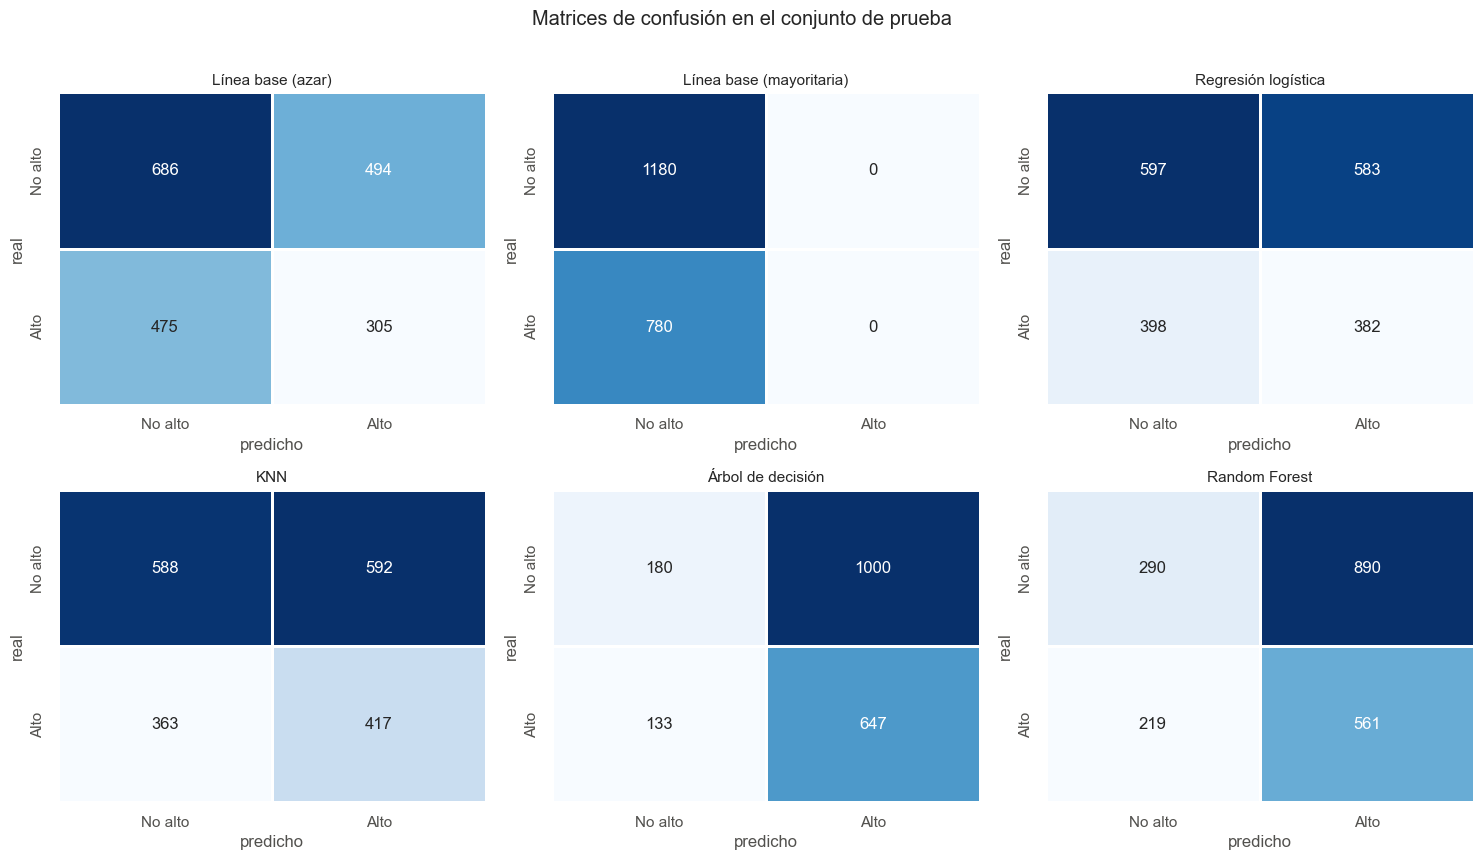

In [25]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))

for ax, (nombre, modelo) in zip(axes.flat, mejores_clf.items()):
    matriz = confusion_matrix(y_clf_prueba, modelo.predict(X_clf_prueba))
    sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                linewidths=2, linecolor="white", annot_kws={"size": 12},
                xticklabels=["No alto", "Alto"], yticklabels=["No alto", "Alto"])
    ax.set_title(nombre)
    ax.set_xlabel("predicho")
    ax.set_ylabel("real")

fig.suptitle("Matrices de confusión en el conjunto de prueba", y=1.01)
plt.tight_layout()
plt.show()

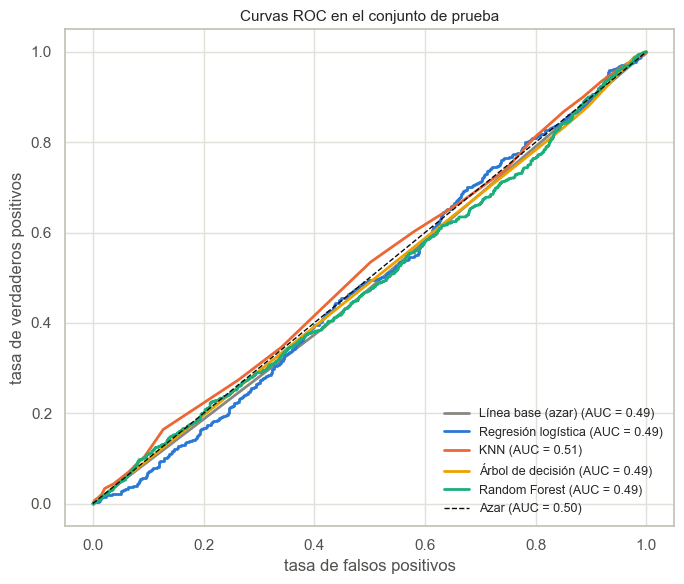

In [26]:
fig, ax = plt.subplots(figsize=(7, 6))
for nombre, modelo in mejores_clf.items():
    if nombre == "Línea base (mayoritaria)":
        continue
    prob = modelo.predict_proba(X_clf_prueba)[:, 1]
    fpr, tpr, _ = roc_curve(y_clf_prueba, prob)
    ax.plot(fpr, tpr, color=COLORES[nombre], linewidth=2,
            label=f"{nombre} (AUC = {roc_auc_score(y_clf_prueba, prob):.2f})")
ax.plot([0, 1], [0, 1], color="#0b0b0b", linestyle="--", linewidth=1, label="Azar (AUC = 0.50)")
ax.set_title("Curvas ROC en el conjunto de prueba")
ax.set_xlabel("tasa de falsos positivos")
ax.set_ylabel("tasa de verdaderos positivos")
ax.legend(frameon=False, loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

Las matrices de confusión muestran que los modelos reparten sus aciertos y errores casi
igual entre las dos clases reales: predicen "alto" con la misma frecuencia a usuarios con y
sin estrés alto. Las curvas ROC se superponen a la diagonal del azar. El conjunto de prueba
confirma lo observado en la validación cruzada.

### Reporte de clasificación del modelo optimizado

In [27]:
print("Random Forest optimizado, conjunto de prueba\n")
print(classification_report(y_clf_prueba, mejores_clf["Random Forest"].predict(X_clf_prueba),
                            target_names=["No alto (0)", "Alto (1)"], digits=3))

Random Forest optimizado, conjunto de prueba

              precision    recall  f1-score   support

 No alto (0)      0.570     0.246     0.343      1180
    Alto (1)      0.387     0.719     0.503       780

    accuracy                          0.434      1960
   macro avg      0.478     0.482     0.423      1960
weighted avg      0.497     0.434     0.407      1960



### Conclusión parcial de clasificación

El estrés alto no puede detectarse a partir del pulso, la oxigenación, los pasos, el sueño
y la actividad de este conjunto. El balanceo con SMOTE evita que los modelos ignoren la
clase minoritaria, pero no puede crear una relación que los datos no contienen. Todos los
clasificadores quedan al nivel del azar (AUC ≈ 0,50).

---

## 4. Prueba de significancia por permutación

Las secciones anteriores muestran métricas al nivel de la línea base, pero falta responder
formalmente si las pequeñas diferencias observadas podrían deberse al azar. La **prueba de
permutación** (`permutation_test_score`) lo resuelve así:

1. Se calcula el desempeño del modelo con las etiquetas reales.
2. Se desordenan las etiquetas al azar (destruyendo cualquier relación con las entradas) y
   se vuelve a entrenar y evaluar con validación cruzada. Esto se repite 100 veces.
3. El **valor p** es la proporción de permutaciones que igualan o superan el desempeño
   real. Un valor p alto significa que el modelo no se distingue de uno entrenado con
   etiquetas sin sentido.

Se aplica a los modelos seleccionados en la sección 5 (Ridge en regresión y árbol de
decisión con SMOTE en clasificación), cuyo bajo costo de entrenamiento permite 100
permutaciones.

In [28]:
N_PERMUTACIONES = 100

pruebas = {
    "Regresión · Ridge (R²)": (buscadores_reg["Ridge"].best_estimator_, X_reg_ent, y_reg_ent, CV_REG, "r2"),
    "Clasificación · Árbol de decisión (ROC AUC)": (
        buscadores_clf["Árbol de decisión"].best_estimator_, X_clf_ent, y_clf_ent, CV_CLF, "roc_auc"),
}

resultados_perm = {}
for nombre, (modelo, X, y, cv, metrica) in pruebas.items():
    real, permutados, p = permutation_test_score(modelo, X, y, cv=cv, scoring=metrica,
                                                  n_permutations=N_PERMUTACIONES,
                                                  random_state=SEMILLA, n_jobs=-1)
    resultados_perm[nombre] = (real, permutados, p)
    print(f"{nombre}: valor real = {real:.4f} | media permutada = {permutados.mean():.4f} | p = {p:.3f}")

Regresión · Ridge (R²): valor real = -0.0036 | media permutada = -0.0012 | p = 1.000


Clasificación · Árbol de decisión (ROC AUC): valor real = 0.4984 | media permutada = 0.4996 | p = 0.594


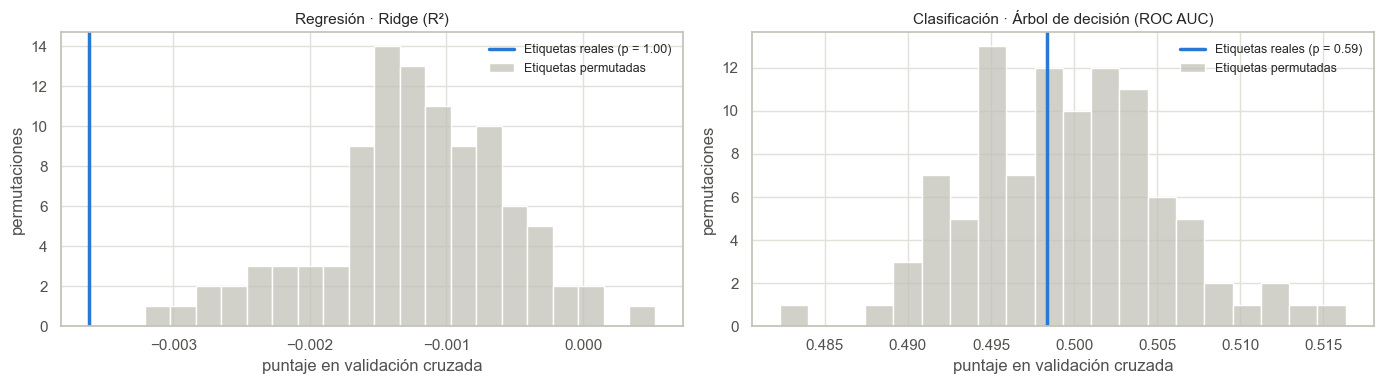

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, (nombre, (real, permutados, p)) in zip(axes, resultados_perm.items()):
    sns.histplot(permutados, bins=20, ax=ax, color="#c3c2b7", label="Etiquetas permutadas")
    ax.axvline(real, color="#2a78d6", linewidth=2.5, label=f"Etiquetas reales (p = {p:.2f})")
    ax.set_title(nombre)
    ax.set_xlabel("puntaje en validación cruzada")
    ax.set_ylabel("permutaciones")
    ax.legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

- **Clasificación:** el AUC obtenido con las etiquetas reales (línea azul) cae en el centro
  de la distribución de las permutaciones (p ≈ 0,59). El árbol de decisión ordena a los
  usuarios igual que uno entrenado con etiquetas desordenadas.
- **Regresión:** el R² real queda incluso **por debajo** de todas las permutaciones
  (p = 1,00). Las diferencias son de milésimas y no tienen significado práctico, pero
  confirman que el modelo entrenado con las respuestas reales no supera a ninguno de los
  entrenados con respuestas al azar.

En ambos casos el valor p está muy por encima del umbral habitual de 0,05. **No hay
evidencia estadística de que los modelos hayan aprendido algo.**

---

## 5. Selección y análisis de resultados

### Tabla resumen: regresión

Media ± desviación estándar en validación cruzada (5 pliegues sobre entrenamiento), valor en
el conjunto de prueba y brecha de sobreajuste (R² de entrenamiento menos R² de validación).

In [30]:
def formato(serie, decimales):
    return serie.map(f"{{:.{decimales}f}}".format)


resumen_reg = pd.DataFrame({
    "Mejores hiperparámetros": {n: str({k.replace('modelo__', ''): v for k, v in b.best_params_.items()})
                                for n, b in buscadores_reg.items()},
    "RMSE CV": formato(tabla_cv_reg["RMSE (CV)"], 4) + " ± " + formato(tabla_cv_reg["RMSE desv."], 4),
    "R² CV": formato(tabla_cv_reg["R2 (CV)"], 4) + " ± " + formato(tabla_cv_reg["R2 desv."], 4),
    "MAE prueba": formato(tabla_prueba_reg["MAE"], 4),
    "MAPE prueba (%)": formato(tabla_prueba_reg["MAPE (%)"], 2),
    "RMSE prueba": formato(tabla_prueba_reg["RMSE"], 4),
    "R² prueba": formato(tabla_prueba_reg["R2"], 4),
    "R² ajustado prueba": formato(tabla_prueba_reg["R2 ajustado"], 4),
    "Brecha R² (entren. - CV)": formato(tabla_cv_reg["R2 (entren.)"] - tabla_cv_reg["R2 (CV)"], 4),
})
resumen_reg.replace("{}", "-")

,Mejores hiperparámetros,RMSE CV,R² CV,MAE prueba,MAPE prueba (%),RMSE prueba,R² prueba,R² ajustado prueba,Brecha R² (entren. - CV)
Línea base,-,1.5064 ± 0.0193,-0.0025 ± 0.0018,1.2051,21.67,1.5194,-0.0017,-0.0044,0.0025
Ridge,{'alpha': 1000},1.5072 ± 0.0194,-0.0036 ± 0.0017,1.2052,21.67,1.5195,-0.0018,-0.0044,0.0038
KNN,"{'n_neighbors': 300, 'weights': 'uniform'}",1.5090 ± 0.0195,-0.0060 ± 0.0013,1.2056,21.68,1.5194,-0.0017,-0.0043,0.0080
Random Forest,"{'max_depth': 2, 'min_samples_leaf': 20}",1.5085 ± 0.0195,-0.0054 ± 0.0016,1.2056,21.67,1.5200,-0.0025,-0.0051,0.0105


### Tabla resumen: clasificación

In [31]:
resumen_clf = pd.DataFrame({
    "Mejores hiperparámetros": {n: str({k.replace('modelo__', ''): v for k, v in b.best_params_.items()})
                                for n, b in buscadores_clf.items()},
    "F1 CV": formato(tabla_cv_clf["F1 (CV)"], 3) + " ± " + formato(tabla_cv_clf["F1 desv."], 3),
    "ROC AUC CV": formato(tabla_cv_clf["ROC AUC (CV)"], 3) + " ± " + formato(tabla_cv_clf["ROC AUC desv."], 3),
    "Recall prueba": formato(tabla_prueba_clf["Recall"], 3),
    "Precision prueba": formato(tabla_prueba_clf["Precision"], 3),
    "F1 prueba": formato(tabla_prueba_clf["F1"], 3),
    "ROC AUC prueba": formato(tabla_prueba_clf["ROC AUC"], 3),
    "Brecha F1 (entren. - CV)": formato(tabla_cv_clf["F1 (entren.)"] - tabla_cv_clf["F1 (CV)"], 3),
})
resumen_clf.replace("{}", "-")

,Mejores hiperparámetros,F1 CV,ROC AUC CV,Recall prueba,Precision prueba,F1 prueba,ROC AUC prueba,Brecha F1 (entren. - CV)
Línea base (azar),-,0.401 ± 0.007,0.499 ± 0.006,0.391,0.382,0.386,0.486,-0.005
Línea base (mayoritaria),-,0.000 ± 0.000,0.500 ± 0.000,0.000,0.000,0.000,0.500,0.000
Regresión logística,{'C': 0.1},0.423 ± 0.018,0.480 ± 0.016,0.490,0.396,0.438,0.489,0.022
KNN,"{'n_neighbors': 75, 'weights': 'uniform'}",0.439 ± 0.009,0.486 ± 0.008,0.535,0.413,0.466,0.514,0.057
Árbol de decisión,"{'max_depth': 3, 'min_samples_leaf': 1}",0.503 ± 0.086,0.498 ± 0.020,0.829,0.393,0.533,0.491,0.017
Random Forest,"{'max_depth': 4, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 100}",0.485 ± 0.042,0.498 ± 0.017,0.719,0.387,0.503,0.486,0.049


### Mejor modelo de regresión: Ridge

**Criterio.** Cuando ningún modelo supera a la línea base, el desempeño deja de ser un
criterio de desempate útil: todas las diferencias están dentro de la variabilidad entre
pliegues. Se elige entonces el modelo que **(1)** tiene el menor RMSE en validación entre
los modelos entrenados, **(2)** no sobreajusta y **(3)** es el más simple de explicar y
mantener. Ridge cumple los tres:

- Su RMSE en validación es el más bajo de los tres modelos entrenados y prácticamente igual
  al de la línea base.
- Su brecha entre entrenamiento y validación es la menor de los modelos entrenados
  (≈ 0,004), frente a KNN (≈ 0,008) y Random Forest (≈ 0,01), cuyo R² de entrenamiento
  algo mayor no se traslada a la validación.
- Sus coeficientes son interpretables y su costo de entrenamiento es mínimo.

**Advertencia:** que sea el mejor de los candidatos no significa que sea útil. Su R² es
≈ 0 y la prueba de permutación no lo distingue del azar, por lo que **no se recomienda
usarlo en producción**: en la práctica, sus predicciones equivalen a informar a todos los
usuarios el promedio de horas de sueño.

### Mejor modelo de clasificación: árbol de decisión con SMOTE

**Criterio.** La búsqueda de hiperparámetros se guió por el F1, fijado antes de entrenar
como métrica del problema. Los resultados mostraron, sin embargo, que el F1 depende en gran
parte de cuántos positivos predice cada modelo (sección 3), por lo que para comparar modelos
distintos se usa como criterio principal el **ROC AUC**, que mide la capacidad de ordenar a los
usuarios por riesgo sin depender del umbral de decisión. Luego se consideran el sobreajuste
y la simplicidad. Se elige el **árbol de decisión (`max_depth = 3`) con SMOTE** porque:

- Comparte el AUC más alto en validación (≈ 0,498, empatado con Random Forest y por encima
  de la regresión logística y KNN).
- Tiene la menor brecha de sobreajuste entre los modelos entrenados (≈ 0,02 en F1), frente a
  Random Forest (≈ 0,05) y KNN (≈ 0,06).
- Es el modelo más simple e interpretable: con tres niveles de profundidad, cada alerta se
  puede explicar con una regla legible, lo que en un sistema de alertas de salud tiene valor
  por sí mismo.
- Obtiene además el F1 más alto en validación y en prueba, aunque por la razón ya explicada
  (marca muchos positivos), y con la mayor variabilidad entre pliegues (± 0,09). Ese F1 no
  debe leerse como mejor capacidad de detección.

**Advertencia:** con un AUC de 0,50 y un valor p alto en la prueba de permutación, el
modelo **no debe usarse para enviar alertas**. Su efecto sería el de un sorteo: notificaría
a usuarios sin estrés alto con la misma probabilidad que a los que sí lo tienen, lo que
erosiona la confianza del usuario en las alertas reales.

---

## 6. Conclusiones

### Qué se hizo

- Se reconstruyó el conjunto limpio de la EP1 y se corrigió una **fuga de datos**: la
  imputación y el escalamiento ahora se ajustan solo con el conjunto de entrenamiento, dentro
  de un pipeline que se reentrena en cada pliegue de la validación cruzada.
- **Regresión:** se predijo la duración del sueño con Ridge, KNN y Random Forest, más una
  línea base, optimizando hiperparámetros con `GridSearchCV` (5 pliegues) y midiendo MSE,
  RMSE, MAE, MAPE, R² y R² ajustado.
- **Clasificación:** se predijo el estrés alto con regresión logística, KNN, árbol de
  decisión y Random Forest, más dos líneas base. Se verificó un desbalance moderado
  (≈ 60/40), se compararon cuatro estrategias de balanceo y se eligió SMOTE. El Random Forest
  se optimizó con una grilla de 32 combinaciones y se midieron matriz de confusión,
  *precision*, *recall*, F1, *balanced accuracy* y ROC AUC.
- Se aplicó un **control positivo** para validar el procedimiento y una **prueba de
  permutación** para evaluar la significancia de los resultados.
- Se seleccionó **Ridge** como mejor modelo de regresión y el **árbol de decisión con
  SMOTE** como mejor modelo de clasificación, con criterios de error en validación, AUC,
  sobreajuste y simplicidad, dado que ninguno se distingue de su línea base.

### Qué se encontró

1. **Ningún modelo supera a su línea base**, ni en validación cruzada ni en prueba. El R²
   de regresión es ≈ 0 y el AUC de clasificación es ≈ 0,50.
2. **El problema está en los datos, no en el procedimiento.** El mismo pipeline obtiene un
   R² alto cuando el objetivo sí depende de las entradas (control positivo), y la prueba de
   permutación no distingue a los modelos de uno entrenado con etiquetas al azar.
3. **Más complejidad solo produjo sobreajuste.** Los modelos más flexibles (Random Forest
   con árboles profundos y KNN con pocos vecinos o con pesos por distancia) memorizan el
   entrenamiento sin mejorar la validación, y la búsqueda de hiperparámetros los empuja hacia la configuración más simple.
4. **La *accuracy* engaña con clases desbalanceadas:** la línea base mayoritaria obtiene la
   mejor *accuracy* sin detectar un solo caso de estrés alto.

### Respuesta a la problemática de negocio

Con los datos disponibles **no es posible** estimar la duración del sueño ni detectar el
estrés alto a partir de las mediciones del smartwatch. Implementar cualquiera de estos
modelos significaría entregar al usuario información con la apariencia de una predicción,
pero equivalente a un promedio o a un sorteo. La recomendación técnica es **no desplegar
ningún modelo** con este conjunto.

### Limitación y recomendaciones

La causa de fondo, ya señalada en la EP1, es el **origen simulado del conjunto**: cada
variable fue generada de forma independiente, por lo que no contiene las relaciones
fisiológicas que existirían en datos reales (por ejemplo, entre estrés y pulso en reposo, o
entre actividad diaria y calidad del sueño). Para abordar el problema se recomienda:

1. **Recolectar datos reales** de usuarios del dispositivo, con su consentimiento.
2. **Agregar la dimensión temporal.** Las mediciones aisladas pierden información; series
   por usuario (pulso nocturno, variabilidad de la frecuencia cardíaca, pasos por hora)
   suelen ser los predictores más fuertes del sueño y del estrés.
3. **Obtener etiquetas confiables:** estrés reportado con un instrumento validado y sueño
   medido con un método de referencia.
4. **Mantener este mismo protocolo** (líneas base, pipeline sin fuga, validación cruzada y
   prueba de permutación) para que cualquier mejora futura sea demostrable y no un efecto
   del azar.

---

### Referencias

- Anthropic. (2026). *Claude* (versión Opus 5.5) [Modelo de lenguaje de gran tamaño].
  https://claude.ai
- Duoc UC. (2025). *Regresión y sus métricas* y *Métricas de clasificación* [Material de la
  asignatura Machine Learning TLY1101].
- Lemaître, G., Nogueira, F. y Aridas, C. K. (2017). Imbalanced-learn: A Python toolbox to
  tackle the curse of imbalanced datasets in machine learning. *Journal of Machine Learning
  Research, 18*(17), 1-5.
- Ojala, M. y Garriga, G. C. (2010). Permutation tests for studying classifier performance.
  *Journal of Machine Learning Research, 11*, 1833-1863.
- Pedregosa, F. et al. (2011). Scikit-learn: Machine learning in Python. *Journal of
  Machine Learning Research, 12*, 2825-2830.